# 03 - What Does the Audience Want? (Clustering)
**Idea:** convert comments into numbers (TF-IDF), then let KMeans put similar comments into the same group.
We use *character n-grams* because Roman Urdu has no fixed spelling (e.g. kitna / kitnaa / ketna).

In [1]:
import sys, pandas as pd, matplotlib.pyplot as plt
sys.path.append("..")          # so that engine.py can be imported
import engine as E
posts = pd.read_csv("../data/posts.csv")
comments = pd.read_csv("../data/comments.csv")
posts = E.add_metrics(posts)   # adds the engagement_rate column

In [2]:
cc = E.cluster_comments(comments, k=8)
cc.cluster_name.value_counts()

cluster_name
discount, suit, hai          1203
mein, delivery, expensive    1075
price, hai, kardo             982
hai, sale, kab                811
nahi, hota, colour            571
details, send, inbox          541
bohat, khoobsurat, rate       512
kitna, hoga                   305
Name: count, dtype: int64

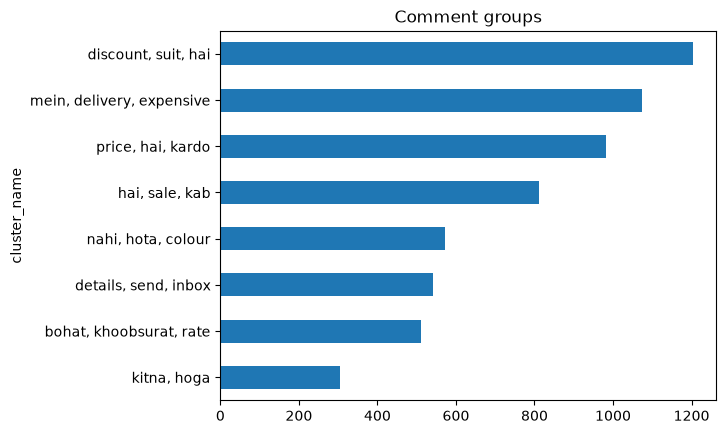

In [3]:
cc.cluster_name.value_counts().sort_values().plot(kind='barh', title='Comment groups')
plt.show()

## Sample comments from each group (read them and think of a better name)

In [4]:
for name in cc.cluster_name.unique():
    print('==', name)
    print(cc[cc.cluster_name==name].comment_text.drop_duplicates().head(6).tolist())
    print()

== price, hai, kardo
['Fabric kaisa hai?', 'Price kya hai?', 'Price bohat zyada hai.', 'Inbox kardo price', 'Itna mehnga kyun hai?', 'price?']

== discount, suit, hai
['Is this available in Karachi?', 'Love this collection', 'Discount code hai koi?', 'Any discount on this suit?', 'Kitne ka hai ye suit?', 'Is it pure cotton lawn?']

== mein, delivery, expensive
['Stock mein hai?', 'Delivery kitne din mein hogi?', 'Too expensive for lawn', 'Lahore delivery time?', 'Islamabad store mein milega?', 'Very beautiful dress!']

== nahi, hota, colour
['Order abhi tak nahi pohancha', 'Quality achi hai ya nahi?', 'Colour fade to nahi hota?']

== hai, sale, kab
['Medium size available hai?', 'Sale kab lag rahi hai?', 'Mashallah gorgeous', 'Ordered last week, still waiting.']

== bohat, khoobsurat, rate
['Bohat khoobsurat!', 'Rate bohat high hai', 'Rate bata dein']

== kitna, hoga
['11.11 pe kitna off hoga?']

== details, send, inbox
['Inbox me details send kar dein.', 'DM details please', 'Price pl

## Experiment: change the number of clusters (k)

In [5]:
for k in [5, 8, 10]:
    t = E.cluster_comments(comments, k=k)
    print('k =', k)
    print(t.cluster_name.value_counts().to_string())
    print()

k = 5
cluster_name
price, bohat, hai             1542
hai, nahi, sale               1537
details, available, hai       1304
discount, suit, hai            844
delivery, dress, beautiful     773

k = 8
cluster_name
discount, suit, hai          1203
mein, delivery, expensive    1075
price, hai, kardo             982
hai, sale, kab                811
nahi, hota, colour            571
details, send, inbox          541
bohat, khoobsurat, rate       512
kitna, hoga                   305

k = 10
cluster_name
mein, delivery, dress      894
discount, suit, hai        844
price, inbox, kardo        725
available, karachi, hai    701
nahi, lawn, expensive      573
details, dein, send        567
hoga, kitna, kyun          485
hai, rahi, sale            482
khoobsurat, bohat, rate    381
week, waiting, ordered     348



## Which topics appear more on which content type?

In [6]:
m = comments.merge(posts[['post_id','content_type','campaign']], on='post_id')
ct = pd.crosstab(m.true_topic, m.content_type, normalize='columns').round(2)
ct

content_type,Influencer Post,Product Photo,Reel,Sale Announcement,Styling Video
true_topic,,,,,
Availability,0.08,0.17,0.10,0.10,0.09
Delivery,0.10,0.12,0.15,0.14,0.14
Discount,0.14,0.16,0.18,0.27,0.22
Fabric,0.09,0.22,0.09,0.10,0.11
Inbox request,0.17,0.07,0.11,0.10,0.10
Praise,0.21,0.09,0.11,0.09,0.10
Price complaint,0.11,0.10,0.14,0.13,0.13
Price inquiry,0.09,0.07,0.11,0.08,0.10


## My conclusions

- - The largest comment groups are about discounts and sales (1,203 comments), delivery (1,075) and price (982), so customers mainly care about price and delivery.
- Discount comments appear most under Sale Announcements (27%), fabric questions under Product Photos (22%), and praise under Influencer Posts (21%).
- Some automatic cluster names are not clear (for example "discount, suit, hai") because common Roman Urdu words like "hai" are not removed. This is a limitation that could be improved with a Roman Urdu stop-word list.